
![Banner](../images/03_03_banner_spatial_analysis_multidimentional.png)

# Spatial Analysis of Multidimensional Raster Data 



Explore how to analyze and visualize multidimensional raster datasets, such as time series of satellite images or climate grids, using the GeoLattice library. This notebook introduces tools and techniques for working with multidimensional data structures commonly found in Earth science and GIS applications.

Five notebooks take a time cube from a definition to a trend and a principal-component summary.

- **Spatial Analysis of Multidimensional Raster Data.** This notebook. What a data cube adds to a flat GeoTIFF, and a first look with `xarray`.
- **Multidimensional Data Management.** Build a Bangladesh temperature cube from ERA NetCDF: daily means, a 16-day composite, a 1 km raster, then the return path from a raster or a table to NetCDF.
- **Multidimensional Data Analysis.** Seasonal means of the watertable, monthly means of NDVI, anomalies against a month-of-year baseline, and the date or duration of a peak.
- **Multidimensional Trend Analysis.** Pixel-wise trends in the Bangladesh watertable, 2000–2020, for the full period, each month, and each season, with Mann-Kendall and Theil-Sen as a check.
- **Multidimensional Principal Components Analysis.** Temporal principal components of monthly temperature, then a multivariate PCA across climate variables for 2018.

Library: `geolattice.spatial_analysis`


## Overview

 A conventional GeoTIFF raster typically represents data in **2 dimensions**: rows × columns (or *y* × *x*), which describe spatial layout on the ground, essentially, images with pixels organized in a grid. These rasters might have a few bands, where each band is a separate 2D array (like RGB channels), but they are fundamentally flat in the sense of describing only one variable or acquisition at a time.
 
In contrast, **multidimensional raster data** (also called data cubes or "hyperstacks") introduce one or more additional axes beyond just *y* and *x*. These new axes can represent time (e.g., repeated observations), depth or elevation (e.g., atmospheric/soil layers), or properties such as wavelength. With multidimensional data, every pixel location (a specific *y*, *x* point) can store not just one value, but a whole **series or stack of values**, for example, a temperature measurement every 6 hours over many years, or imagery from multiple satellite bands at each date. These extra axes unlock much richer analysis, letting you slice the dataset in time, extract profiles across depth, or compute changes and trends, all within a single, efficiently structured file.

```
2-D raster:     value[y, x]
3-D cube:       value[time, y, x]          ← common climate / remote-sensing case
4-D+ cube:      value[time, depth, y, x]   ← oceans, atmosphere, soil profiles
```

### Building blocks

| Concept | Meaning | Example in this tutorial |
|---|---|---|
| **Variable** | A measured or derived field | `t2m` (2 m air temperature) |
| **Dimension** | An axis of the array | `time`, `latitude`, `longitude` |
| **Coordinate** | Labels along a dimension | `2000-01-01T03:00`, `26.5°N`, `90.0°E` |
| **Attribute** | Metadata (units, CRS notes, history) | `units = "K"`, CF conventions |

### Why it matters in GIS and Earth science

- Store **time series of maps** (temperature, NDVI, groundwater) in one file instead of hundreds of GeoTIFFs.
- Subset by date, depth, or region without rewriting the full archive.
- Aggregate (daily -> monthly), compute anomalies, and find "date of maximum" along a dimension.
- Interoperate with CF-compliant NetCDF used by climate models and reanalyses (ERA5, CMIP, …).

> **ArcGIS note:** Esri's *Multidimensional Raster* / Image Analyst tools map closely to
> `geolattice.spatial_analysis.multidimensional_raster`. This series uses the open-source API
> backed by `xarray`.


## Common formats

| Format | Typical use | Notes |
|---|---|---|
| **NetCDF** (`.nc`) | Climate / weather cubes | CF conventions; primary format in this series |
| **Zarr** (`.zarr`) | Cloud-friendly chunked arrays | Good for large remote datasets |
| **GRIB / GRIB2** | NWP model output | Often converted to NetCDF first |
| **HDF4 / HDF5** | Satellite products (MODIS, …) | Hierarchical groups / datasets |
| **Multi-band GeoTIFF** | Time or band stacks on disk | One band ≈ one time slice; weaker metadata than NetCDF |
| **OPeNDAP / THREDDS** | Remote streaming | Open subsets without downloading the full cube |

Recommended analysis outputs in `geolattice` are **NetCDF** or **Zarr**. Multi-band
GeoTIFF remains useful for mapping and for tools that expect classic raster bands.

### Demo dataset

We use ECMWF ERA **2 m temperature** merged for Bangladesh:

`Data/03_spatial_analysis/NetCDF/t2m_2000_2018.nc`

- Variable: `t2m` (Kelvin)
- Dimensions: `time` × `latitude` × `longitude`
- Coverage: roughly 2000-2018 (years **2004-2006** missing), 3-hourly steps


## Multidimensional functions in GeoLattice

All tools live in `geolattice.spatial_analysis` (implemented in
`geolattice.spatial_analysis.multidimensional_raster`). They mirror ArcGIS
*Multidimension* / *Image Analyst* workflows and operate on an in-memory
`MultidimensionalRaster` backed by an `xarray.Dataset`.

Install extras when needed:

```bash
pip install "geolattice[multidim]"
```

### Core object

| Name | Role |
|---|---|
| `MultidimensionalRaster` | In-memory cube: `.variables`, `.get_dimension_names()`, `.get_dimension_values()`, `.sel()` / `.isel()`, `.to_netcdf()` / `.to_zarr()`, `MultidimensionalRaster.open(path)` |
| `MultidimensionalRasterError` | Raised when a multidimensional operation fails |

### Create / open layers

| Function | Description | ArcGIS analog |
|---|---|---|
| `make_multidimensional_raster_layer` | Open NetCDF, GRIB, HDF, Zarr, or OPeNDAP; optional variable + dimension filters | *Make Multidimensional Raster Layer* |
| `make_netcdf_raster_layer` | Read one NetCDF variable as a raster layer | *Make NetCDF Raster Layer* |
| `make_netcdf_feature_layer` | Read NetCDF coords / variables as a point table (`DataFrame`) | *Make NetCDF Feature Layer* |
| `make_netcdf_table_view` | Flatten NetCDF variables to a tabular view | *Make NetCDF Table View* |
| `make_opendap_raster_layer` | Stream a cube from an OPeNDAP / THREDDS URL | *Make OPeNDAP Raster Layer* |

### Manage, subset, and convert

| Function | Description | ArcGIS analog |
|---|---|---|
| `subset_multidimensional_raster` | Subset by variable, dimension ranges / values, and/or spatial extent | *Subset Multidimensional Raster* |
| `merge_multidimensional_rasters` | Combine cubes along a dimension (e.g. years) | *Merge Multidimensional Rasters* |
| `build_multidimensional_info` | Build a cube from a mosaic / GeoTIFF file series + dimension values | *Build Multidimensional Info* |
| `build_multidimensional_transpose` | Restructure storage for fast per-pixel time-series reads | *Build Multidimensional Transpose* |
| `copy_multidimensional_raster` | Copy / convert between supported formats (NetCDF, Zarr, multi-band GeoTIFF, …) | *Copy Raster* (multidim) |
| `multidimensional_filter` | On-the-fly subset filter (no write unless a destination is set) | Multidimensional filter function |

### Import / export NetCDF

| Function | Description | ArcGIS analog |
|---|---|---|
| `raster_to_netcdf` | Export a multidimensional raster to `.nc` | *Raster to NetCDF* |
| `feature_to_netcdf` | Export point features / a `DataFrame` to NetCDF | *Feature to NetCDF* |
| `table_to_netcdf` | Export a table to NetCDF | *Table to NetCDF* |

### Temporal analysis

| Function | Description | ArcGIS analog |
|---|---|---|
| `aggregate_multidimensional_raster` | Aggregate along a dimension (`MEAN`, `MAX`, …; `HOURLY` … `YEARLY` intervals) | *Aggregate Multidimensional Raster* |
| `generate_multidimensional_anomaly` | Anomalies vs mean / median / external baseline (`DIFFERENCE`, `%`, z-score) | *Generate Multidimensional Anomaly* |
| `find_argument_statistics` | Dimension value where a statistic occurs (e.g. date of max, duration above threshold) | *Find Argument Statistics* |
| `generate_trend_raster` | Per-pixel trend (polynomial, harmonic, Mann-Kendall, …) | *Generate Trend Raster* |
| `predict_using_trend_raster` | Project values at new dimension coordinates from a trend model | *Predict Using Trend Raster* |
| `aggregate_function` / `anomaly_function` / `trend_function` | Raster-function style (in-memory) wrappers for aggregate / anomaly / trend | Raster functions |

### Change detection, PCA, and space-time cubes

| Function | Description | ArcGIS analog |
|---|---|---|
| `analyze_changes_using_ccdc` | Continuous Change Detection and Classification-style breaks | *Analyze Changes Using CCDC* |
| `analyze_changes_using_landtrendr` | LandTrendr-style temporal segmentation | *Analyze Changes Using LandTrendr* |
| `detect_change_using_change_analysis_raster` | Extract change date, magnitude, or count from CCDC / LandTrendr output | *Detect Change Using Change Analysis Raster* |
| `multidimensional_principal_components` | PCA / EOF-style decomposition across a dimension | *Multidimensional Principal Components* |
| `create_space_time_cube_from_multidimensional_raster` | Convert a gridded series into a space-time cube structure | *Create Space Time Cube* |

### Extract, sample, and summarize

| Function | Description | ArcGIS analog |
|---|---|---|
| `temporal_profile` | Pixel or zone time series for profiling / charts | Temporal Profile |
| `sample_multidimensional` | Sample the cube at point locations for every slice | *Sample* (multidim) |
| `zonal_statistics_as_table` | Per-slice zonal statistics over polygons | *Zonal Statistics as Table* (multidim) |

### Where they appear in this series

| Group | Primarily used in |
|---|---|
| Open / subset / NetCDF I/O / `build_multidimensional_info` | `03_03_00`, `03_03_01` |
| Aggregate, anomaly, argument statistics | `03_03_02` |
| Trend, CCDC / LandTrendr, PCA, space-time cube | `03_03_03`, `03_03_04` |

Typical pipeline:

```
Make Multidimensional Raster Layer
        -> Subset / Merge / Build Info
        -> Aggregate -> Anomaly or Trend (or CCDC / LandTrendr)
        -> Zonal Statistics / Sample / Temporal Profile
        -> Raster to NetCDF (or Zarr / GeoTIFF)
```


## Setup

Locate the repository root, preload GDAL bindings if needed, and import the
multidimensional helpers used in the hands-on sections below.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for optional GDAL preloading.
import os  # environment variables for GDAL/PROJ data paths
import ctypes  # preload libgdal into the process when needed
import warnings  # silence noisy third-party warnings in the tutorial
from pathlib import Path  # filesystem paths for locating the NetCDF

# Jupyter kernels do not load ~/.bashrc: preload user-local GDAL so osgeo works.
_GDAL_PREFIX = Path.home() / ".local" / "share" / "gdal-prefix"  # local GDAL install prefix
_GDAL_LIBDIR = _GDAL_PREFIX / "lib"  # directory containing libgdal
_GDAL_SO = _GDAL_LIBDIR / "libgdal.so.39"  # shared library file to preload
if _GDAL_SO.is_file():  # only adjust the environment when the local build exists
    os.environ["PATH"] = f"{_GDAL_PREFIX / 'bin'}{os.pathsep}{os.environ.get('PATH', '')}"  # prepend GDAL bin
    _ld = os.environ.get("LD_LIBRARY_PATH", "")  # existing LD_LIBRARY_PATH value
    os.environ["LD_LIBRARY_PATH"] = f"{_GDAL_LIBDIR}{os.pathsep}{_ld}" if _ld else str(_GDAL_LIBDIR)  # prepend lib dir
    _gdal_data = _GDAL_PREFIX / "share" / "gdal"  # GDAL_DATA support files
    _proj_data = _GDAL_PREFIX / "share" / "proj"  # PROJ datum / grid files
    if _gdal_data.is_dir():
        os.environ.setdefault("GDAL_DATA", str(_gdal_data))  # set GDAL_DATA if not already defined
    if _proj_data.is_dir():
        os.environ.setdefault("PROJ_DATA", str(_proj_data))  # PROJ 9+ data directory
        os.environ.setdefault("PROJ_LIB", str(_proj_data))  # legacy PROJ data directory
    ctypes.CDLL(str(_GDAL_SO), mode=ctypes.RTLD_GLOBAL)  # load libgdal into this process


# Third-party numeric / multidimensional stack.
import numpy as np  # array ops for masks and datetime comparisons
import pandas as pd  # timestamps and table previews
import xarray as xr  # labeled NetCDF / multidimensional arrays
import matplotlib.pyplot as plt  # figure and axes creation for maps and series

warnings.filterwarnings("ignore")  # keep the tutorial output readable

# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Multidimensional raster helpers used in this introduction notebook.
from geolattice.spatial_analysis import (
    MultidimensionalRaster,  # cube wrapper around an xarray Dataset
    make_multidimensional_raster_layer,  # open NetCDF as MultidimensionalRaster
    subset_multidimensional_raster,  # crop by dimension ranges
)

NC_PATH = ROOT / "Data" / "03_spatial_analysis" / "NetCDF" / "t2m_2000_2018.nc"  # ERA5 2 m temperature cube

print(f"Repo:   {ROOT}")  # confirm repository root
print(f"NetCDF: {NC_PATH} exists={NC_PATH.is_file()}")  # confirm the NetCDF is present


Repo:   /home/zia207/Github/GeoLattice
NetCDF: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/NetCDF/t2m_2000_2018.nc exists=True


### Verify the public API

List every multidimensional name exported from `geolattice.spatial_analysis`:


In [2]:
# Confirm the multidimensional API (run after Setup).
from geolattice import spatial_analysis as pgr  # public spatial_analysis namespace

# Names that should be re-exported for the multidimensional workflow series.
_multidim_names = [
    "MultidimensionalRaster",  # cube wrapper class
    "MultidimensionalRasterError",  # package-specific error type
    "make_multidimensional_raster_layer",  # open a cube from disk
    "make_netcdf_raster_layer",  # NetCDF to raster layer helper
    "make_netcdf_feature_layer",  # NetCDF to feature layer helper
    "make_netcdf_table_view",  # NetCDF to table view helper
    "make_opendap_raster_layer",  # OpenDAP remote cube helper
    "subset_multidimensional_raster",  # dimension subsetting
    "merge_multidimensional_rasters",  # merge cubes
    "build_multidimensional_info",  # build metadata / info tables
    "build_multidimensional_transpose",  # transpose dimensions
    "raster_to_netcdf",  # GeoTIFF series to NetCDF
    "feature_to_netcdf",  # features to NetCDF
    "table_to_netcdf",  # tables to NetCDF
    "copy_multidimensional_raster",  # copy a cube
    "aggregate_multidimensional_raster",  # temporal aggregation
    "generate_multidimensional_anomaly",  # anomaly from a baseline
    "find_argument_statistics",  # argmax / argmin along time
    "generate_trend_raster",  # pixel-wise trend surfaces
    "predict_using_trend_raster",  # project a fitted trend forward
    "analyze_changes_using_ccdc",  # CCDC change analysis
    "analyze_changes_using_landtrendr",  # LandTrendr change analysis
    "detect_change_using_change_analysis_raster",  # change detection helper
    "multidimensional_principal_components",  # temporal / multivariate PCA
    "create_space_time_cube_from_multidimensional_raster",  # space-time cube export
    "aggregate_function",  # aggregation function registry
    "anomaly_function",  # anomaly function registry
    "trend_function",  # trend function registry
    "multidimensional_filter",  # dimensional filters
    "temporal_profile",  # extract a temporal profile
    "zonal_statistics_as_table",  # zonal stats over a cube
    "sample_multidimensional",  # sample cube values at points
]

print(f"{'Name':48} {'Available':10} First-line docstring")  # table header
print("-" * 100)  # separator line
for name in _multidim_names:
    obj = getattr(pgr, name, None)  # look up the public attribute
    ok = obj is not None  # True if the name is exported
    doc = (obj.__doc__ or "").strip().splitlines()[0] if ok and obj.__doc__ else ""  # first docstring line
    print(f"{name:48} {str(ok):10} {doc[:60]}")  # name, availability, short doc


Name                                             Available  First-line docstring
----------------------------------------------------------------------------------------------------
MultidimensionalRaster                           True       In-memory multidimensional raster backed by an ``xarray.Data
MultidimensionalRasterError                      True       Raised when a multidimensional raster operation cannot be co
make_multidimensional_raster_layer               True       Create a multidimensional raster layer from NetCDF, GRIB, HD
make_netcdf_raster_layer                         True       Read a NetCDF variable as a raster layer
make_netcdf_feature_layer                        True       Read NetCDF coordinates / variables as a point feature table
make_netcdf_table_view                           True       Read NetCDF variables as a tabular view
make_opendap_raster_layer                        True       Stream a multidimensional raster from an OPeNDAP / THREDDS s
subset_multi

## Open with xarray (raw view)

`xarray` is the array model underneath `MultidimensionalRaster`. Opening the NetCDF shows
dimensions, coordinates, data variables, and global attributes.


In [3]:
# Open the ERA5 t2m NetCDF with xarray for a raw cube view.
ds = xr.open_dataset(NC_PATH)  # lazy-open the NetCDF as an xarray Dataset
ds  # display the Dataset summary in the notebook


<xarray.Dataset> Size: 366MB
Dimensions:    (time: 45552, latitude: 49, longitude: 41)
Coordinates:
  * time       (time) datetime64[ns] 364kB 2000-01-01T03:00:00 ... 2019-01-01
  * latitude   (latitude) float32 196B 26.5 26.38 26.25 ... 20.75 20.62 20.5
  * longitude  (longitude) float32 164B 87.5 87.62 87.75 ... 92.25 92.38 92.5
Data variables:
    t2m        (time, latitude, longitude) float32 366MB ...
Attributes:
    Conventions:  CF-1.6
    history:      2020-08-23 15:13:57 GMT by grib_to_netcdf-2.18.0: grib_to_n...
    title:        2 metre temperature (t2m) 2000-2018
    source:       Merged from yearly ERA NetCDF files (data_YYYY_fc.nc)
    note:         Years 2004-2006 not present in source directory

In [4]:
# Print dimensions, coordinates, variable attributes, and value ranges.
print("Dimensions:", dict(ds.sizes))  # dimension name -> length
print("Coordinates:", list(ds.coords))  # coordinate names
print("Variables:", list(ds.data_vars))  # data variable names
print()  # blank line before attribute dump
print("Variable attrs (t2m):")  # CF attributes for air temperature
for k, v in ds["t2m"].attrs.items():
    print(f"  {k}: {v}")  # print each attribute key/value
print()  # blank line before ranges
print("Time range:", pd.to_datetime(ds.time.values[0]), "->", pd.to_datetime(ds.time.values[-1]))  # first/last time
print("Lat range: ", float(ds.latitude.min()), "->", float(ds.latitude.max()))  # latitude extent
print("Lon range: ", float(ds.longitude.min()), "->", float(ds.longitude.max()))  # longitude extent
print("Time steps:", ds.sizes["time"], "(3-hourly)")  # number of time steps


Dimensions: {'time': 45552, 'latitude': 49, 'longitude': 41}
Coordinates: ['longitude', 'latitude', 'time']
Variables: ['t2m']

Variable attrs (t2m):
  units: K
  long_name: 2 metre temperature

Time range: 2000-01-01 03:00:00 -> 2019-01-01 00:00:00
Lat range:  20.5 -> 26.5
Lon range:  87.5 -> 92.5
Time steps: 45552 (3-hourly)


## Open with `MultidimensionalRaster`

`make_multidimensional_raster_layer` (ArcGIS *Make Multidimensional Raster Layer*) wraps
the dataset and exposes variables / dimension helpers used by later tools.


In [5]:
# Open the same NetCDF as a GeoLattice MultidimensionalRaster (t2m only).
mdr = make_multidimensional_raster_layer(NC_PATH, variables=["t2m"])  # wrap t2m as a cube layer
# Equivalent: MultidimensionalRaster.open(NC_PATH)

print(mdr)  # print the MultidimensionalRaster summary
print()  # blank line
print("Variables:", mdr.variables)  # variables retained in the layer
print("Dimension names:", mdr.get_dimension_names("t2m"))  # dimensions of t2m
print()  # blank line

times = mdr.get_dimension_values("time")  # full time coordinate values
print("First 5 times:", times[:5])  # preview the start of the series
print("Last time:    ", times[-1])  # last time stamp
print("n_time:       ", len(times))  # number of time steps


MultidimensionalRaster(variables=[t2m], dims={time: 45552, latitude: 49, longitude: 41})

Variables: ['t2m']
Dimension names: ['time', 'latitude', 'longitude']

First 5 times: ['2000-01-01T03:00:00.000000000' '2000-01-01T06:00:00.000000000'
 '2000-01-01T09:00:00.000000000' '2000-01-01T12:00:00.000000000'
 '2000-01-01T15:00:00.000000000']
Last time:     2019-01-01T00:00:00.000000000
n_time:        45552


### 2-D vs multidimensional (same pixel)

Pick one grid cell near Dhaka and compare a single map slice with the temperature
**time series** at that location.


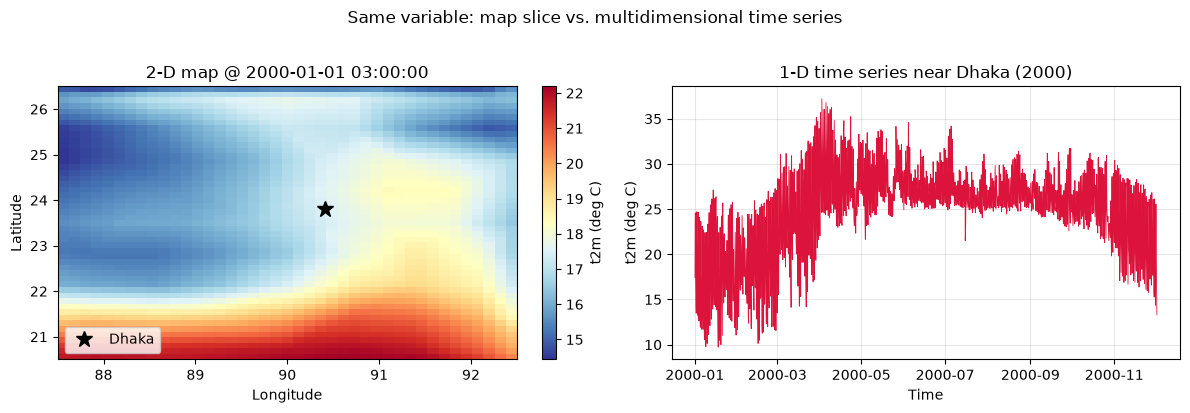

Nearest cell: lat=23.750, lon=90.375
2000 mean / min / max (deg C): 24.85 / 9.73 / 37.21


In [6]:
# Approximate Dhaka coordinates for a point sample.
LAT, LON = 23.81, 90.41  # approximate Dhaka latitude / longitude

# One time slice -> behaves like a classic 2-D raster map.
slice_2d = ds["t2m"].isel(time=0) - 273.15  # Kelvin -> deg C for the first time step

# Full series at nearest grid point -> 1-D time series.
series = ds["t2m"].sel(latitude=LAT, longitude=LON, method="nearest") - 273.15  # nearest cell to Dhaka

fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # map panel + time-series panel

im = axes[0].imshow(
    slice_2d.values,  # 2-D temperature field
    origin="upper",  # match NetCDF row order
    extent=[
        float(ds.longitude.min()),  # west
        float(ds.longitude.max()),  # east
        float(ds.latitude.min()),  # south
        float(ds.latitude.max()),  # north
    ],
    aspect="auto",  # stretch to the axes
    cmap="RdYlBu_r",  # temperature colormap
)
axes[0].set_title(f"2-D map @ {pd.to_datetime(ds.time.values[0])}")  # time stamp title
axes[0].set_xlabel("Longitude")  # x-axis label
axes[0].set_ylabel("Latitude")  # y-axis label
axes[0].plot(LON, LAT, "k*", markersize=12, label="Dhaka")  # mark Dhaka
axes[0].legend(loc="lower left")  # show the Dhaka marker legend
fig.colorbar(im, ax=axes[0], label="t2m (deg C)", fraction=0.046)  # temperature colorbar

# Plot a manageable window (first year of data) for readability.
t0 = pd.to_datetime(series.time.values[0])  # first timestamp in the series
mask = (series.time >= np.datetime64(f"{t0.year}-01-01")) & (
    series.time < np.datetime64(f"{t0.year + 1}-01-01")
)  # boolean mask for the first calendar year
series_yr = series.sel(time=mask)  # subset to that year
axes[1].plot(series_yr.time.values, series_yr.values, lw=0.6, color="crimson")  # time series line
axes[1].set_title(f"1-D time series near Dhaka ({t0.year})")  # series title
axes[1].set_xlabel("Time")  # x-axis label
axes[1].set_ylabel("t2m (deg C)")  # y-axis label
axes[1].grid(True, alpha=0.3)  # light grid for reading values

fig.suptitle("Same variable: map slice vs. multidimensional time series", y=1.02)  # shared title
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render both panels

print(
    f"Nearest cell: lat={float(series.latitude):.3f}, lon={float(series.longitude):.3f}"
)  # confirm sampled cell
print(
    f"{t0.year} mean / min / max (deg C): "
    f"{float(series_yr.mean()):.2f} / {float(series_yr.min()):.2f} / {float(series_yr.max()):.2f}"
)  # annual summary stats


## Subset by dimension

Working with the full cube (~45k time steps) is rarely necessary for exploration.
Subset by time (and optionally space) with `subset_multidimensional_raster` or
`dimension_ranges` when opening.


MultidimensionalRaster(variables=[t2m], dims={time: 248, latitude: 49, longitude: 41})
MultidimensionalRaster(variables=[t2m], dims={time: 56, latitude: 49, longitude: 41})


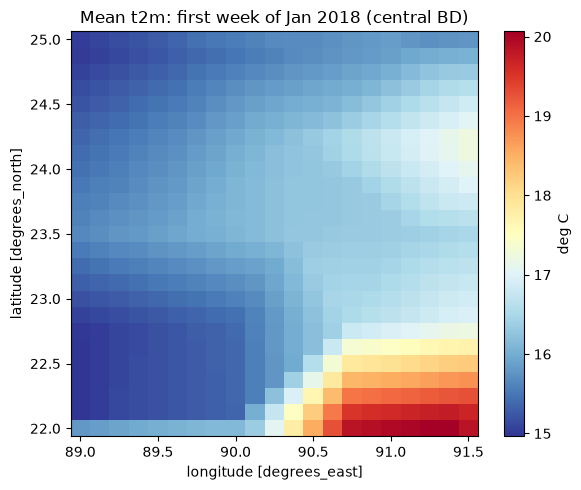

Daily means shape (time, lat, lon): (7, 25, 21)


In [7]:
# Keep only January 2018 while opening the cube.
mdr_jan = make_multidimensional_raster_layer(
    NC_PATH,  # source NetCDF
    variables=["t2m"],  # keep air temperature only
    dimension_ranges={
        "time": {"start": "2018-01-01", "end": "2018-01-31 23:59:59"},  # January 2018 window
    },
)
print(mdr_jan)  # confirm the January subset

# Or subset an already-open layer to the first week of January.
mdr_week = subset_multidimensional_raster(
    mdr_jan,  # January cube
    dimension_definitions={
        "time": {"start": "2018-01-01", "end": "2018-01-07 23:59:59"},  # first week
    },
)
print(mdr_week)  # confirm the week subset

# Spatial window around central Bangladesh + daily mean for a quick map.
t2m_week = mdr_week.dataset["t2m"].sel(
    latitude=slice(25.0, 22.0),  # north -> south (lat decreases in this file)
    longitude=slice(89.0, 91.5),  # west -> east window
)
daily = t2m_week.resample(time="1D").mean() - 273.15  # daily mean in deg C

fig, ax = plt.subplots(figsize=(6, 5))  # single map figure
daily.mean("time").plot(ax=ax, cmap="RdYlBu_r", cbar_kwargs={"label": "deg C"})  # week-mean map
ax.set_title("Mean t2m: first week of Jan 2018 (central BD)")  # map title
plt.tight_layout()  # reduce unused whitespace
plt.show()  # render the map

print("Daily means shape (time, lat, lon):", daily.shape)  # confirm daily cube shape


## From cube -> table (preview)

NetCDF can also be viewed as a table of point samples: useful before interpolation or
joining to vector features (covered in depth in `03_03_01`).


In [8]:
# Small extract: one day, coarse print as a flat table of grid cells.
day = ds["t2m"].sel(time="2018-06-15T12:00:00", method="nearest") - 273.15  # nearest noon slice in deg C
table = day.to_dataframe(name="t2m_c").reset_index()  # flatten lat/lon into rows
print(table.head(10))  # preview the first rows
print(f"... {len(table):,} grid cells for this time slice")  # total cell count


   latitude  longitude                time      t2m_c
0      26.5     87.500 2018-06-15 12:00:00  28.615997
1      26.5     87.625 2018-06-15 12:00:00  28.366028
2      26.5     87.750 2018-06-15 12:00:00  28.048035
3      26.5     87.875 2018-06-15 12:00:00  27.982178
4      26.5     88.000 2018-06-15 12:00:00  27.932526
5      26.5     88.125 2018-06-15 12:00:00  27.904449
6      26.5     88.250 2018-06-15 12:00:00  27.875275
7      26.5     88.375 2018-06-15 12:00:00  27.843964
8      26.5     88.500 2018-06-15 12:00:00  27.812134
9      26.5     88.625 2018-06-15 12:00:00  27.710083
... 2,009 grid cells for this time slice


## Conceptual workflow in this series

```
NetCDF / GRIB / file series
        │
        ▼
make_multidimensional_raster_layer / build_multidimensional_info
        │
        ├─► subset_multidimensional_raster / merge / copy / *_to_netcdf
        │         (management: 03_03_01)
        │
        ├─► aggregate_multidimensional_raster
        ├─► generate_multidimensional_anomaly
        ├─► find_argument_statistics
        └─► generate_trend_raster / CCDC / LandTrendr / PCA
                  (analysis: 03_03_02 and advanced)
        │
        ▼
NetCDF / multi-band GeoTIFF / maps / tables
```

### Key takeaways

1. Multidimensional rasters are **variables + dimensions + coordinates**, not just pixels.
2. Prefer **NetCDF / Zarr** when time (or depth) metadata must travel with the data.
3. `xarray` is the engine; `MultidimensionalRaster` and the functions in **§5** are the
   ArcPy-style facade used throughout pyGeoSpatial.
4. Always **subset early**: full reanalysis cubes are large; work on the years / regions you need.

### Next notebooks

- **`03_03_01`**: ERA `t2m` -> daily means -> Bangladesh clip -> 16-day composites -> 1000 m GeoTIFF / NetCDF  
- **`03_03_02`**: Seasonal watertable means, monthly NDVI, anomalies, and argument statistics


## Cleanup

Close the open NetCDF dataset when you finish.


In [9]:
# Close the xarray Dataset handle when finished.
ds.close()  # release the NetCDF file handle
print("Done.")  # status line


Done.
